In [35]:
from torchvision import datasets,transforms
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader

In [36]:
Path.cwd()

PosixPath('/content')

In [37]:
data_path=Path.cwd()/"dataset/kmnist"

In [38]:
import os
os.makedirs(data_path,exist_ok=True)

In [39]:
train_transform=transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0,translate=(0.1,0.1)),
    transforms.ToTensor()
])


In [40]:
test_transform=transforms.Compose([
    transforms.ToTensor()
])

In [41]:
train_dataset=datasets.KMNIST(root=data_path,train=True,download=True,transform=train_transform)

100%|██████████| 18.2M/18.2M [00:24<00:00, 745kB/s] 
100%|██████████| 29.5k/29.5k [00:00<00:00, 131kB/s]
100%|██████████| 3.04M/3.04M [00:02<00:00, 1.03MB/s]
100%|██████████| 5.12k/5.12k [00:00<00:00, 3.71MB/s]


In [42]:
test_dataset=datasets.KMNIST(root=data_path,train=False,download=True,transform=test_transform)

In [43]:
train_loader=DataLoader(train_dataset,batch_size=128,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=256,shuffle=False)
idx=15

In [44]:
original_img=train_dataset.data[idx]

In [45]:
label=train_dataset.targets[idx].item()
aug_img,aug_label=train_dataset[idx]

In [46]:
print("Index:",idx)
print("Lable:",label,"->",train_dataset.classes[label])
print("Original shape:", tuple(original_img.shape))
print("Augmented shape:",tuple(aug_img.shape))
print("Augmented pixel range:",aug_img.min().item(),"to",aug_img.max().item())

Index: 15
Lable: 6 -> ma
Original shape: (28, 28)
Augmented shape: (1, 28, 28)
Augmented pixel range: 0.0 to 1.0


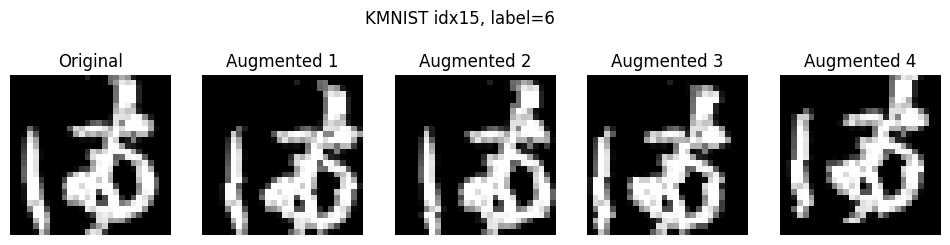

In [47]:
fig,axes=plt.subplots(1,5,figsize=(12,3))
axes[0].imshow(original_img,cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")
for i in range(1,5):
  img,_=train_dataset[idx]
  axes[i].imshow(img.squeeze(0),cmap="gray")
  axes[i].set_title(f"Augmented {i}")
  axes[i].axis("off")
plt.suptitle(f"KMNIST idx{idx}, label={label}")
plt.show()

In [48]:
images,labels=next(iter(train_loader))
print("Batch images shape:",images.shape)
print("Batch labeles shape:",labels.shape)

Batch images shape: torch.Size([128, 1, 28, 28])
Batch labeles shape: torch.Size([128])


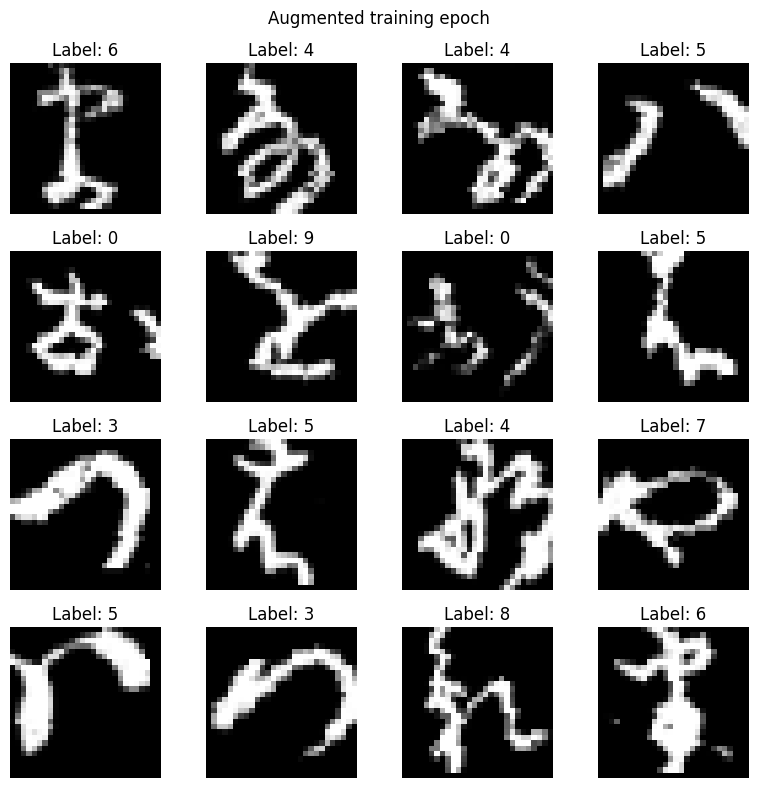

In [49]:
fig,axes=plt.subplots(4,4,figsize=(8,8))
for ax,img,lbl in zip(axes.flatten(),images[:16],labels[:16]):
  ax.imshow(img.squeeze(0),cmap="gray")
  ax.set_title(f"Label: {lbl.item()}")
  ax.axis("off")
plt.suptitle("Augmented training epoch")
plt.tight_layout()
plt.show()